In [ ]:
Mall Customer Segmentation Analysis/ Сегментация клиентов торгового центра 

In [1]:
#Loading the packages 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [2]:
# Dataset
df = pd.read_csv("Mall_Customers.csv")
df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


Exploratory Data Analysis(EDA)/ Разведочный Анализ Данных

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Genre                   200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
None
       CustomerID         Age  Annual Income (k$)  Spending Score (1-100)
count  200.000000  200.000000          200.000000              200.000000
mean   100.500000   38.850000           60.560000               50.200000
std     57.879185   13.969007           26.264721               25.823522
min      1.000000   18.000000           15.000000                1.000000
25%     50.750000   28.750000           41.500000               34.750000
50%    100.500000   36.000000    

/var/folders/9k/9kdgb6_95jg_37gqzzgn8ptr0000gn/T/ipykernel_3975/1855660573.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Genre', data=df, palette='Set2')


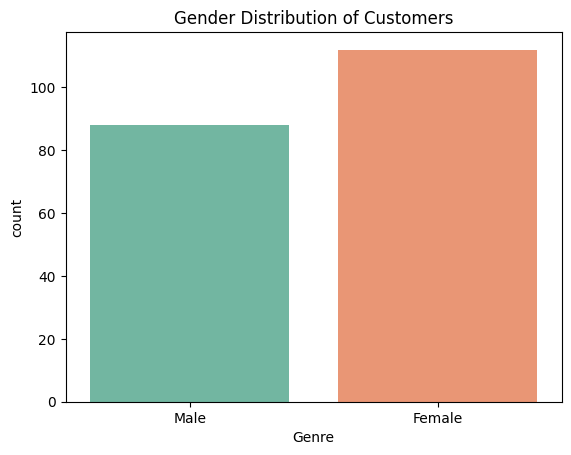

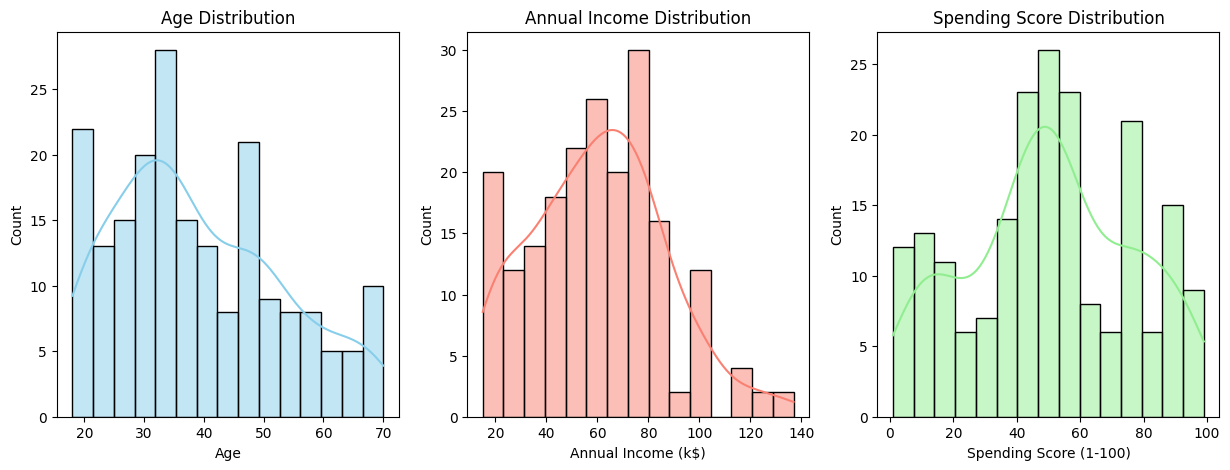

In [4]:
# overview
print(df.info())
print(df.describe())


sns.countplot(x='Genre', data=df, palette='Set2')
plt.title("Gender Distribution of Customers")
plt.show()


fig, axes = plt.subplots(1, 3, figsize=(15,5))
sns.histplot(df['Age'], bins=15, kde=True, ax=axes[0], color='skyblue')
sns.histplot(df['Annual Income (k$)'], bins=15, kde=True, ax=axes[1], color='salmon')
sns.histplot(df['Spending Score (1-100)'], bins=15, kde=True, ax=axes[2], color='lightgreen')
axes[0].set_title("Age Distribution")
axes[1].set_title("Annual Income Distribution")
axes[2].set_title("Spending Score Distribution")
plt.show()


The dataset contains 200 rows. There are no missing/null values.
Age: 
Age distribution ranges from 18 to 70 years old, with a mean of 38,85(39) years, illustrating a balanced mix of young adults and middle-aged customers. Mostly, according to the outcomes, the customers are ranged between 20 and 40 years old, with a fewer customers at the age above 50. 
Gender:
Provided dataset contains slightly more female customers(55%). This outcome shows that both groups are equally represented, but female-oriented advertisements, marketing may bring more success. 
Annual Income:
Annual Income distribution varies from 15k to 137k dollars, estimating the mean of approximately 61k USD. The histogram demonstrates the prevalent earnings of 40-80k USD, which means that the middle-income group dominates. 
Spending Score:
Spending score is a value that represents how much a customer may spend when attending the mall. Higher score means that customer tend to purchase goods from a mall more frequently. The distribution shows a clear division of groups: low spenders(0-30) and high spenders(70-100). In this case, the average has estimated a score of 50. Thus, customers' spending behaviour is not directly dependent on income, both luxury and middle income customers exist. This insight highlight the significance of using clustering for further analysis of target customers group.

Набор данных содержит 200 строк. Пропущенные и нулевые значения отсутвуют.
Возраст:
Распредение возраста посететилей варьируется от 18 до 70 лет, в то время как среднее значение составляет 38.85(39) лет, что отображает сбалансированное соотношение молодых и клиентов среднеге возраста. Согласно результатам, большая часть клиентов находиться в диапазоне 20-40 лет. Клиентов старше 50 значительно меньше.
Пол:
В предоставленном наборе данных немного больше женщин (55%). Этот результат показывает, что обе группы представлены достаточно равномерно, однако ориентированная на женщин реклама и маркетинг могут принести больше успеха.
Годовой доход:
Распределение годового дохода варьируется от 15000 до 137000 долларов США, среднее значение составляет примерно 61000 долларов США. Гистограмма демонстрирует преобладающий диапазон доходов 40000–80000 долларов США, что означает доминирование группы клиентов со средним уровнем дохода.
Индекс трат(Spending Score):
Spending Score — это показатель, отражающий, сколько клиент может тратить при посещении торгового центра. Высокое значение означает, что клиент чаще совершает покупки и тратит больше. Распределение показывает чёткое деление на группы: мало тратившие (0–30) и активные покупатели (70–100). В данном случае среднее значение составило 50. Таким образом, покупательское поведение клиентов не напрямую зависит от дохода: в выборке присутствуют как состоятельные покупатели, так и клиенты со средним доходом. Этот вывод подчёркивает важность использования кластеризации для дальнейшего анализа целевых групп клиентов.

Elbow Method / Метод Локтя

In [5]:
# selecting the features
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

#standartising the values for Kmeans
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

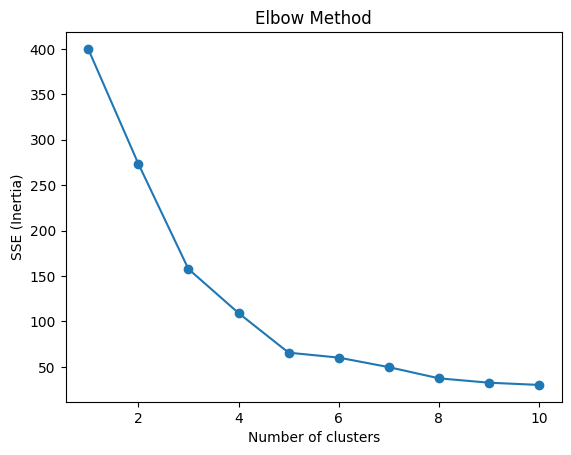

In [6]:
sse = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42)
    km.fit(X_scaled)
    sse.append(km.inertia_)

plt.plot(range(1, 11), sse, marker='o')
plt.xlabel("Number of clusters")
plt.ylabel("SSE (Inertia)")
plt.title("Elbow Method")
plt.show()

SSE ( sum of squared errors) is the value which explains how close data points are to their cluster centers. 
The curve above illustrates that SSE ( sum of squared errors) is decreasing each time the number of clusters increase. The elbow point shows the best balance between simplicty and accuracy of clusters. Consequently, the nest value for k is 3. 200 customers were grouped in 3 clusters, where each cluster represents a different types of income and spending patterns.

SSE(сумма квадратов ошибок) - показатель, обьясняющий насколько близки точки данных к центрам своих кластеров. Иллюстрация выше, показывает как значение SSE уменьшается,в то время как число кластеров возрастает. Точка «локтя» показывает наилучший баланс между простотой и точностью кластеров. Следовательно, оптимальное значение k равно 3.
200 клиентов были сгруппированы в 3 кластера, где каждый кластер отражает различные типы дохода и моделей трат.


In [7]:
kmeans = KMeans(n_clusters=3, random_state=42)
df['Cluster'] = kmeans.fit_predict(X_scaled)

df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,2
1,2,Male,21,15,81,2
2,3,Female,20,16,6,2
3,4,Female,23,16,77,2
4,5,Female,31,17,40,2


Cluster Statistics/ Статистика по кластерам

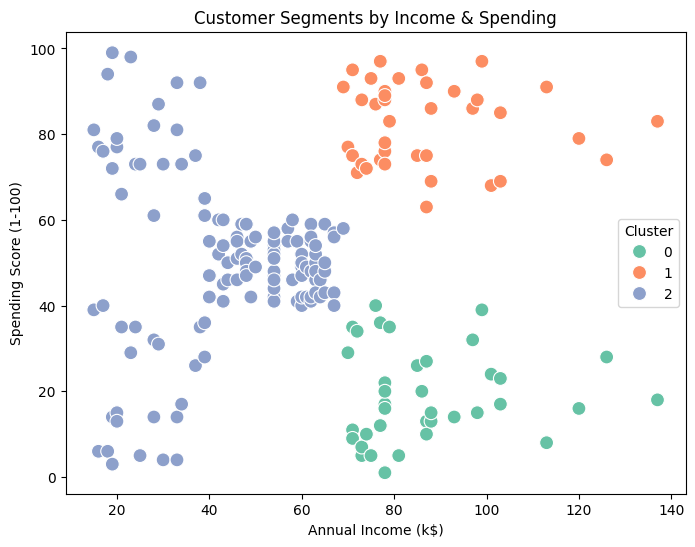

In [8]:
plt.figure(figsize=(8,6))
sns.scatterplot(
    data=df, 
    x='Annual Income (k$)', 
    y='Spending Score (1-100)', 
    hue='Cluster', 
    palette='Set2', 
    s=100
)
plt.title("Customer Segments by Income & Spending")
plt.show()

In [9]:
cluster_summary = df.groupby('Cluster')[['Age','Annual Income (k$)','Spending Score (1-100)']].mean()
cluster_counts = df['Cluster'].value_counts()

print("Cluster Counts:\n", cluster_counts)
print("\nCluster Summary:\n", cluster_summary)

Cluster Counts:
 Cluster
2    123
1     39
0     38
Name: count, dtype: int64

Cluster Summary:
                Age  Annual Income (k$)  Spending Score (1-100)
Cluster                                                       
0        40.394737           87.000000               18.631579
1        32.692308           86.538462               82.128205
2        40.325203           44.154472               49.829268


There are 3 clusters provided on a plot. 
Green shows those customers who tend to be low spending, while being high-income customers.
Red defines high-income and high-spending customers.
Blue shows the middle income and average spending clients. 
As it is observable from cluster counts, the blue(2) is a prevalent group of customers. This conclusion helps to provide some solutions for marketing strategies since the first high income groups are less common. For instance, businesses can design strategies like loyalty programs, memberships that tend to encorage spending more.

Анализ выделил три различных кластера клиентов:
Зелёный (Кластер 0): Клиенты с высоким доходом, но низкими расходами. Это обеспеченные, но осторожные покупатели.
Красный (Кластер 1): Клиенты с высоким доходом и высокими расходами. Это премиальный сегмент, представляющий самых ценных покупателей.
Синий (Кластер 2): Клиенты со средним доходом и средним уровнем трат. Это наибольшая группа, составляющая основную часть клиентской базы.
Синий кластер(2) является доминирующим по сравнению с кластерами 0 и 1. Изходя из этого, для привличения клиентов 
первой и нулевой группы бизнес может создавать решения, как программы лояльности, для привличения клиентов вышеперечисленных категорий.

Conclusions/Итоги анализа
    1.	Cluster Insights
	The clustering process successfully defined three distinct groups of customers with different income and spending behaviors.
	These groups provide a clear understanding of how customers behave and what strategies may suit them best.
	2.	Business Value
	The analysis highlights potential for increased profit through better customer engagement.
	Segmentation allows for targeted marketing campaigns, such as loyalty programs for premium customers, discounts for mid-tier groups, and exclusive offers for cautious wealthy customers.
	3	Future Work
	While K-Means clustering provided valuable insights, future analysis could apply other methods (e.g., Hierarchical Clustering, DBSCAN) to validate results and uncover additional patterns.
	Including more features such as Age, Gender, or frequency of visits may further refine customer segmentation.

1. Кластеризация клиентов выявила три группы с различными доходами и потребительским поведением, что позволяет оптимизировать стратегии работы с каждым сегментом.
2. Сегментация открывает возможности для увеличения прибыли за счет таргетированных маркетинговых кампаний: программы лояльности для премиум-клиентов, скидки и акции для основной группы, и эксклюзивные предложения для обеспеченных, но сдержанных покупателей.
3. Для повышения надежности кластеризации, рекомендуется использовать альтернативные методы (иерархическая кластеризация, DBSCAN) и включить дополнительные признаки (возраст, пол, частота покупок) для более точной сегментации и расширения практической ценности анализа.
 